In [1]:
import json
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = "freckll_survey_output"  

planet_dirs = sorted(glob.glob(f"{BASE_DIR}/planet_*"))
print(f"Found {len(planet_dirs)} planet folders")

records = []
for pdir in planet_dirs:
    with open(f"{pdir}/params.json", "r") as f:
        params = json.load(f)
    params["planet_dir"] = pdir
    records.append(params)

df = pd.DataFrame(records)
print(df.shape)
print(df.columns.tolist())
print(df.head())
print("\nSuccess rate overall:", df["success"].mean())

Found 8426 planet folders
(8426, 7)
['Teq_K', 'Rp_Rj', 'Mp_Mj', 'Rstar_Rs', 'kzz_cm2_s', 'success', 'planet_dir']
         Teq_K     Rp_Rj     Mp_Mj  Rstar_Rs     kzz_cm2_s  success  \
0  2389.681331  1.469384  3.729786  1.020688  1.000000e+10     True   
1  1484.971787  1.451352  4.979452  1.131525  1.000000e+10     True   
2  2618.214384  0.485121  0.300789  1.977049  1.000000e+10     True   
3  2182.893678  0.169645  1.300105  0.626291  1.000000e+10     True   
4  2934.180349  0.398559  2.134453  1.153056  1.000000e+10     True   

                          planet_dir  
0  freckll_survey_output/planet_0000  
1  freckll_survey_output/planet_0001  
2  freckll_survey_output/planet_0002  
3  freckll_survey_output/planet_0003  
4  freckll_survey_output/planet_0005  

Success rate overall: 1.0


In [3]:
print("Total planets:", len(df))
print("Failed count:", (~df["success"]).sum())
print("Success rate:", df["success"].mean())
print()
print("Teq range in this dataset:", df["Teq_K"].min(), "-", df["Teq_K"].max())
print()
print("Failed planets' Teq values:")
print(df[~df["success"]]["Teq_K"].sort_values().values)

Total planets: 8426
Failed count: 0
Success rate: 1.0

Teq range in this dataset: 437.5839685460138 - 2999.9379551277743

Failed planets' Teq values:
[]


In [4]:
G = 6.674e-8  # cgs
R_jup_cm = 7.1492e9
M_jup_g = 1.898e30
k_B = 1.380649e-16  # erg/K
mu_typical = 2.3 * 1.6726e-24  # g, typical H2/He atmosphere mean molecular weight

df["Mp_g"] = df["Mp_Mj"] * M_jup_g
df["Rp_cm"] = df["Rp_Rj"] * R_jup_cm
df["g_cgs"] = G * df["Mp_g"] / df["Rp_cm"]**2
df["scale_height_km"] = (k_B * df["Teq_K"] / (mu_typical * df["g_cgs"])) / 1e5

print("Surface gravity (cgs):")
print(df["g_cgs"].describe())
print()
print("Scale height (km):")
print(df["scale_height_km"].describe())
print()
print("Mp_Mj range:", df["Mp_Mj"].min(), "-", df["Mp_Mj"].max())
print("Rp_Rj range:", df["Rp_Rj"].min(), "-", df["Rp_Rj"].max())
print()
print("Number of planets with g < 200 cgs (our earlier 'watch this one' threshold):", (df["g_cgs"] < 200).sum())
print("Number of planets with g < 500 cgs:", (df["g_cgs"] < 500).sum())
print("Lowest 10 gravity values:")
print(df.nsmallest(10, "g_cgs")[["Teq_K", "Mp_Mj", "Rp_Rj", "g_cgs"]])

Surface gravity (cgs):
count    8.426000e+03
mean     3.670209e+04
std      9.825032e+04
min      1.239265e+03
25%      3.179231e+03
50%      6.750203e+03
75%      2.186551e+04
max      1.166306e+06
Name: g_cgs, dtype: float64

Scale height (km):
count    8426.000000
mean      135.806723
std       143.788279
min         0.338928
25%        26.435840
50%        90.148721
75%       195.853871
max       857.755306
Name: scale_height_km, dtype: float64

Mp_Mj range: 0.10066170606958776 - 4.999914193366971
Rp_Rj range: 0.1000365550814997 - 1.9998997891636139

Number of planets with g < 200 cgs (our earlier 'watch this one' threshold): 0
Number of planets with g < 500 cgs: 0
Lowest 10 gravity values:
            Teq_K     Mp_Mj     Rp_Rj        g_cgs
4466  1840.304059  1.133988  1.505934  1239.264596
8412  2157.562248  0.516156  1.015618  1240.186715
3575  2070.971747  0.439294  0.936934  1240.236281
5346  2969.387550  1.298231  1.609260  1242.415395
7077  1998.764856  0.720610  1.198938  12

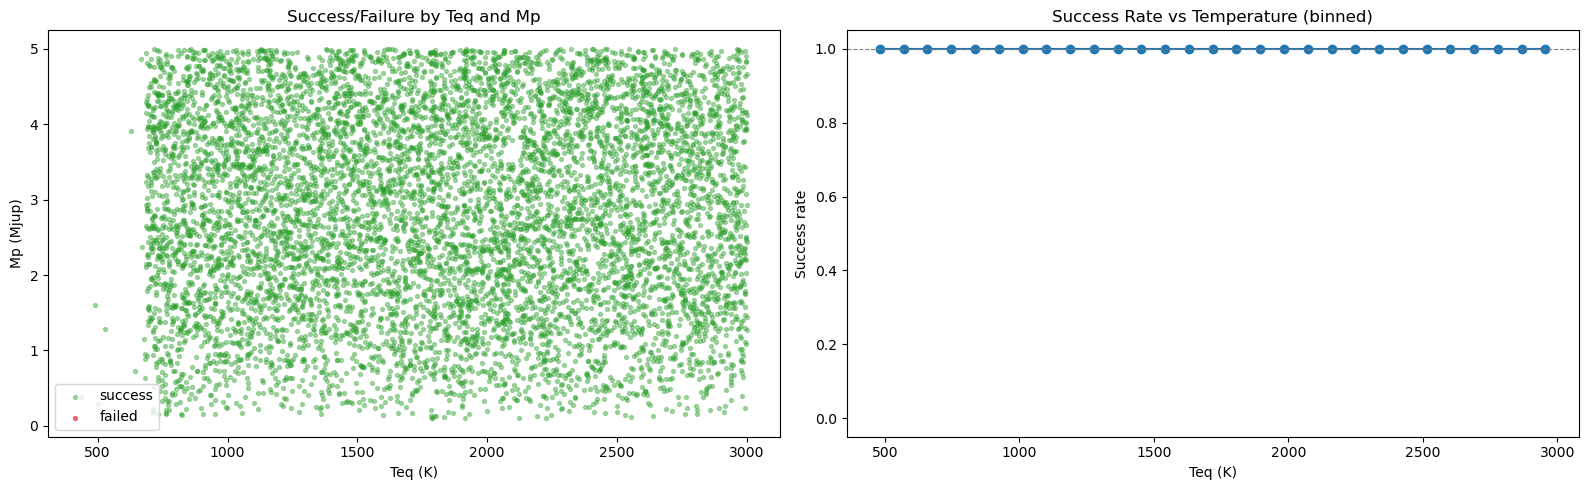

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# scatter: every planet, colored by success/fail
ax = axes[0]
failed = df[~df["success"]]
succeeded = df[df["success"]]
ax.scatter(succeeded["Teq_K"], succeeded["Mp_Mj"], s=8, alpha=0.4, color="tab:green", label="success")
ax.scatter(failed["Teq_K"], failed["Mp_Mj"], s=8, alpha=0.6, color="tab:red", label="failed")
ax.set_xlabel("Teq (K)")
ax.set_ylabel("Mp (Mjup)")
ax.set_title("Success/Failure by Teq and Mp")
ax.legend()

# success rate binned by temperature, to see the band shape directly
ax = axes[1]
bins = np.linspace(df["Teq_K"].min(), df["Teq_K"].max(), 30)
df["Teq_bin"] = pd.cut(df["Teq_K"], bins)
success_rate_by_bin = df.groupby("Teq_bin", observed=True)["success"].mean()
bin_centers = [interval.mid for interval in success_rate_by_bin.index]

ax.plot(bin_centers, success_rate_by_bin.values, marker="o", color="tab:blue")
ax.set_xlabel("Teq (K)")
ax.set_ylabel("Success rate")
ax.set_title("Success Rate vs Temperature (binned)")
ax.axhline(1.0, color="gray", ls="--", lw=0.8)
ax.set_ylim(-0.05, 1.05)

plt.tight_layout()
plt.savefig("teq_vs_success.png", dpi=150)
plt.show()

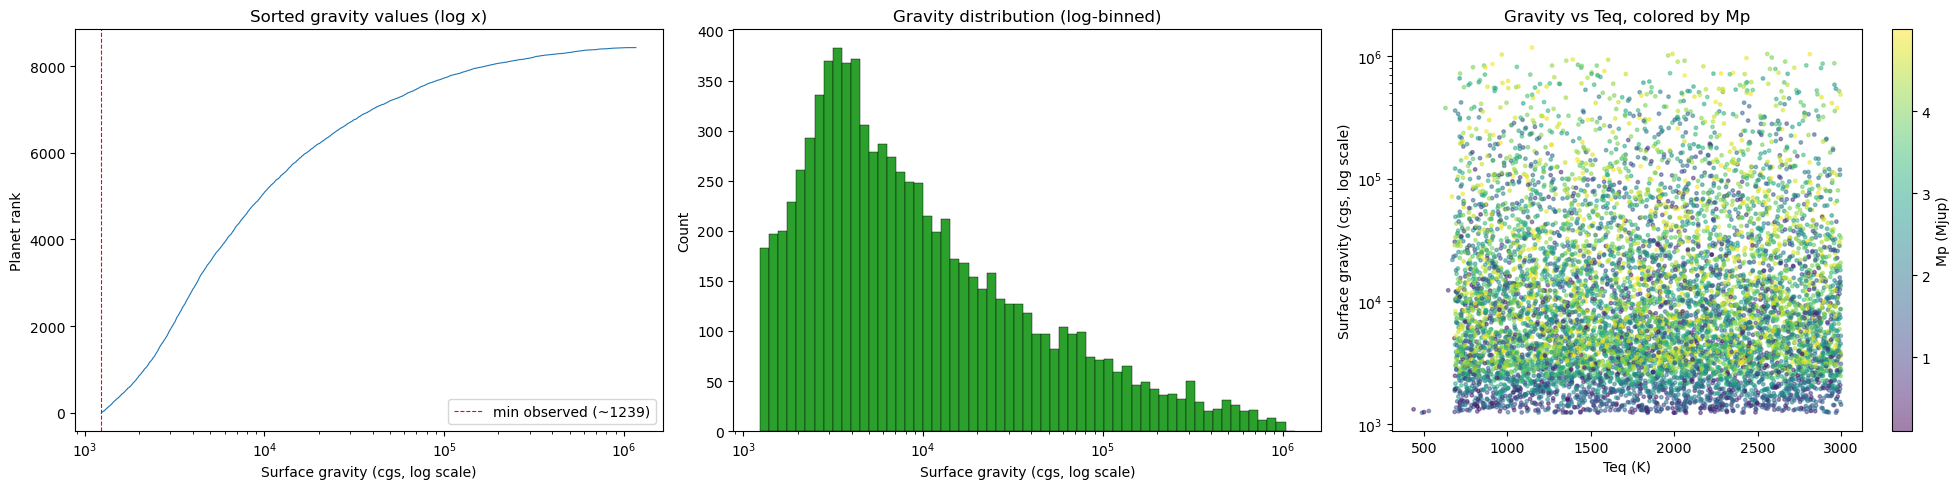

Lowest 30 gravity values, sorted:
[1239.26459571 1240.18671463 1240.23628085 1242.41539518 1242.43810537
 1242.46415923 1242.98799821 1243.11534038 1244.25751583 1244.40328246
 1245.48550839 1245.69702025 1246.72262709 1247.37086001 1248.29220219
 1248.75628153 1249.73749586 1250.36512324 1251.08486689 1251.38564145
 1251.46250612 1252.63722692 1253.5104757  1255.9551375  1257.1299405
 1257.22412462 1260.54535149 1260.60328195 1261.82122438 1262.04510169]


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. sorted gravity values -- gaps show up as flat/jump segments
ax = axes[0]
sorted_g = np.sort(df["g_cgs"].values)
ax.plot(sorted_g, np.arange(len(sorted_g)), color="tab:blue", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel("Surface gravity (cgs, log scale)")
ax.set_ylabel("Planet rank")
ax.set_title("Sorted gravity values (log x)")
ax.axvline(1239, color="red", ls="--", lw=0.8, label="min observed (~1239)")
ax.legend()

# 2. histogram, log-spaced bins
ax = axes[1]
log_bins = np.logspace(np.log10(df["g_cgs"].min()), np.log10(df["g_cgs"].max()), 60)
ax.hist(df["g_cgs"], bins=log_bins, color="tab:green", edgecolor="black", linewidth=0.3)
ax.set_xscale("log")
ax.set_xlabel("Surface gravity (cgs, log scale)")
ax.set_ylabel("Count")
ax.set_title("Gravity distribution (log-binned)")

# 3. gravity vs Teq scatter, colored by Mp for context
ax = axes[2]
sc = ax.scatter(df["Teq_K"], df["g_cgs"], c=df["Mp_Mj"], s=6, alpha=0.5, cmap="viridis")
ax.set_yscale("log")
ax.set_xlabel("Teq (K)")
ax.set_ylabel("Surface gravity (cgs, log scale)")
ax.set_title("Gravity vs Teq, colored by Mp")
plt.colorbar(sc, ax=ax, label="Mp (Mjup)")

plt.tight_layout()
plt.savefig("gravity_distribution.png", dpi=150)
plt.show()

# also print the actual gap, if any, near the low end
print("Lowest 30 gravity values, sorted:")
print(np.sort(df["g_cgs"].values)[:30])